# Loading the dataset and understanding the data

The bookshop wants clusters of books that share the same topic or theme, derived from the `description` field

In [1]:
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

# load the bookshop dataset
df = pd.read_csv("CAB330_asm2_datasets 2/Dataset4Task3_26.csv")

# set random_state to be consistent
rs = 42

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Title          5000 non-null   str  
 1   description    5000 non-null   str  
 2   authors        4909 non-null   str  
 3   publisher      4293 non-null   str  
 4   publishedDate  4982 non-null   str  
 5   categories     4744 non-null   str  
dtypes: str(6)
memory usage: 234.5 KB


In [2]:
print(f"Rows: {df.shape[0]:,}  Columns: {df.shape[1]}")
print()
print("Missing values per column:")
print(df.isna().sum().to_string())
print()
print("First raw description (first 300 characters):")
print(df.loc[0, "description"][:300])

Rows: 5,000  Columns: 6

Missing values per column:
Title              0
description        0
authors           91
publisher        707
publishedDate     18
categories       256

First raw description (first 300 characters):
Philip Nel takes a fascinating look into the key aspects of Seuss's career - his poetry, politics, art, marketing, and place in the popular imagination." "Nel argues convincingly that Dr. Seuss is one of the most influential poets in America. His nonsense verse, like that of Lewis Carroll and Edward


The description column will be used for classification as it contains the most relevant information about the content of the book

# Preprocessing the description field

In [3]:
import string
import re

from nltk.corpus import stopwords as sw
from nltk.corpus import wordnet as wn
from nltk import WordNetLemmatizer, pos_tag, sent_tokenize, wordpunct_tokenize

lemmatizer = WordNetLemmatizer()
punct = set(string.punctuation)

# no provided stopwords, so just using the default NLTK
stopwords = set(sw.words("english"))

def lemmatize(token, tag):
    tag = {
        'N': wn.NOUN,
        'V': wn.VERB,
        'R': wn.ADV,
        'J': wn.ADJ
    }.get(tag[0], wn.NOUN)
    
    return lemmatizer.lemmatize(token, tag)

def cab_tokenizer(document):
    # init token list
    tokens = []

    # split the document into sentences
    for sent in sent_tokenize(str(document)):
        # split doc into tokens, then create part of speech tag for each
        for token, tag in pos_tag(wordpunct_tokenize(sent)):
            # preprocess and remove unnecessary characters
            token = token.lower()
            token = token.strip()
            token = token.strip('_')
            token = token.strip('*')

            # If stopword, ignore
            if token in stopwords:
                continue

            # If punctuation, ignore
            if all(char in punct for char in token):
                continue
            
            # keeps useful tokens which aren't standalone characters
            is_word = len(token) >= 2 and token.isalpha()

            # returns true if:
            # 1. A 4-digit year or decade from 1500 to 2099, with optional 's' (e.g., '1999', '1980s', '2024')
            # 2. A 1- to 2-digit ordinal number (e.g., '1st', '2nd', '3rd', '21st', '19th')
            is_era = bool(re.match(r'^(1[5-9]\d{2}|20\d{2})s?$|^\d{1,2}(st|nd|rd|th)$', token))
            if not (is_word or is_era):
                continue

            # inflections of words are not important,
            # lemmatize the token and add to tokens list
            lemma = lemmatize(token, tag)
            tokens.append(lemma)

    return tokens

In [4]:
books = df.copy()
books["processed_description"] = books["description"].apply(cab_tokenizer)

for i in range(10):
    print(f"[{i}] {' '.join(books.loc[i, 'processed_description'])[:200]}")

[0] philip nel take fascinating look key aspect seuss career poetry politics art marketing place popular imagination nel argue convincingly dr seuss one influential poet america nonsense verse like lewis 
[1] resource include twelve principle understand small church worship fifteen practice plan worship few people suggestion congregational study
[2] julia thomas find life spin control death husband richard julia turn minister comfort find fall passion forbid church heath spark man god busy take care quadriplegic wife seriously injure sever car ac
[3] church christ biblical ecclesiology today respect biblical scholar everett ferguson present genuine biblical theology church systematically examine new testament teaching existence meaning purpose chu
[4] story child st hyacinth dominican plant faith poland lithuania russia work many miracle go rome meet st dominic one first receive hand habit newly establish order friar preacher novitiate make religio
[5] wardell recall experience foreign

In [5]:
token_counts = books["processed_description"].map(len)
n_empty = int((token_counts == 0).sum())
avg_tokens = float(token_counts.mean())

print(f"Descriptions: {len(books):,}")
print(f"Empty after initial preprocessing: {n_empty}")

Descriptions: 5,000
Empty after initial preprocessing: 3


In [6]:
# Checking for extreme small descriptions to see if there are placeholders
missing_rows = books.loc[token_counts < 5]
for index, row in missing_rows.iterrows():
    print(f"  row {index}: description={row['description']!r}  title={row['Title'][:60]}")

  row 95: description='"I\'d rather eat nails than bend to his will!"'  title=Sheikh (Mills & Boon Historical)
  row 160: description='No description available.'  title=The Jester's Quest (Winds of Light, Book 7)
  row 172: description='Description: Movie Press Kits.'  title=Run Wild, Run Free
  row 182: description='Includes bibliographical references and index.'  title=Social Research Methods: Qualitative and Quantitative Approa
  row 304: description='No description available.'  title=West Indians in West Africa, 1808-1880: The African Diaspora
  row 317: description='No description available.'  title=Dance of Darkness (Winds of Light #8)
  row 492: description='Bonded Leather binding'  title=Trails I Rode (American Autobiography)
  row 598: description='Introduction by Michael Meyer'  title=Frederick Douglass: The Narrative and Selected Writings
  row 695: description='No Marketing Blurb'  title=The Thin Red Line (BFI Film Classics)
  row 700: description='Presents an introduction 

In [7]:
# Some placeholder-like values found
# remove the genuinely useless descriptions
# without being too strict and degrading the dataset
# i.e. explicitly no description available
PLACEHOLDER_PATTERNS = [
    r"^no description available\.?$",
    r"^no marketing blurb\.?$",
    r"^publisher description\.?$",
]
PLACEHOLDER = re.compile("|".join(PLACEHOLDER_PATTERNS), re.IGNORECASE)

description_text = books["description"].fillna("").str.strip()
is_placeholder = description_text.map(lambda text: bool(PLACEHOLDER.search(text)))
has_no_tokens = token_counts == 0
flag = is_placeholder | has_no_tokens

print(f"Descriptions: {len(books):,}")
print(f"  Placeholder descriptions: {int(is_placeholder.sum())}")
print(f"  Descriptions with no tokens: {int(has_no_tokens.sum())}")
print(f"  Rows to remove: {int(flag.sum())} ({flag.mean():.2%} of the dataset)")

Descriptions: 5,000
  Placeholder descriptions: 8
  Descriptions with no tokens: 3
  Rows to remove: 11 (0.22% of the dataset)


In [8]:
# remove the 3 rows with empty/ useless descriptions
books = books.loc[~flag].reset_index(drop=True)
print(f"Rows after removal: {len(books)}")

Rows after removal: 4989


In [9]:
token_counts = books["processed_description"].map(len)
avg_tokens = float(token_counts.mean())

print(f"Descriptions used for clustering: {len(books):,}")
print(f"Average processed length: {avg_tokens:.2f} tokens")
print(f"Median: {token_counts.median():.0f}")
print()
print(token_counts.describe().round(2).to_string())

Descriptions used for clustering: 4,989
Average processed length: 64.38 tokens
Median: 46

count    4989.00
mean       64.38
std        59.35
min         1.00
25%        20.00
50%        46.00
75%        93.00
max       922.00


Design the `calculate_tf_df` and `plot_zipf` functions

In [10]:
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

def calculate_tf_df(tokenised_documents):
    """Return (term, TF, DF) rows for a collection of token lists, highest TF first"""
    tf_counts = Counter()
    df_counts = Counter()

    for document in tokenised_documents:
        tf_counts.update(document) # every occurence
        df_counts.update(set(document)) # once per document

    rows = [(term, tf_counts[term], df_counts[term]) for term in tf_counts]
    rows.sort(key=lambda row: (-row[1], -row[2], row[0]))
    return rows

In [11]:
tf_df_rows = calculate_tf_df(books["processed_description"])
tf_df_table = pd.DataFrame(tf_df_rows, columns=["term", "TF", "DF"])
tf_df_table["DF_share"] = (tf_df_table["DF"] / len(books)).round(4)

# rows must be ordered by TF and a term can never occur in more
# documents than it has occurences
ordered_by_tf = bool(tf_df_table["TF"].is_monotonic_decreasing)
tf_at_least_df = bool((tf_df_table["TF"] >= tf_df_table["DF"]).all())
assert ordered_by_tf and tf_at_least_df, "the TF/DF table failed its consistency check"

print(f"Distinct terms: {len(tf_df_table):,}")
print(f"Sorted by TF descending: {ordered_by_tf}")
print(f"TF >= DF for every term: {tf_at_least_df}")
print()
print(tf_df_table.head(12).to_string(index=False))
print()
print(f"Maximum DF share: {tf_df_table['DF_share'].max():.4f}")
print(f"Terms with DF share > 0.7: {int((tf_df_table['DF_share'] > 0.7).sum())}") # means appearing in more than 70% of descriptions

Distinct terms: 32,644
Sorted by TF descending: True
TF >= DF for every term: True

   term   TF   DF  DF_share
   book 2625 1547    0.3101
    new 1641 1077    0.2159
   life 1577 1016    0.2036
     de 1461  239    0.0479
    one 1289  966    0.1936
   work 1252  785    0.1573
  world 1211  887    0.1778
include 1168  909    0.1822
  story  981  680    0.1363
   make  952  762    0.1527
   time  944  715    0.1433
  first  942  766    0.1535

Maximum DF share: 0.3101
Terms with DF share > 0.7: 0


In [30]:
print(f"Total tokens in the corpus: {token_counts.sum():,}")
print(f"Descriptions with five tokens or fewer: {int((token_counts <= 5).sum())}")

Total tokens in the corpus: 321,169
Descriptions with five tokens or fewer: 83


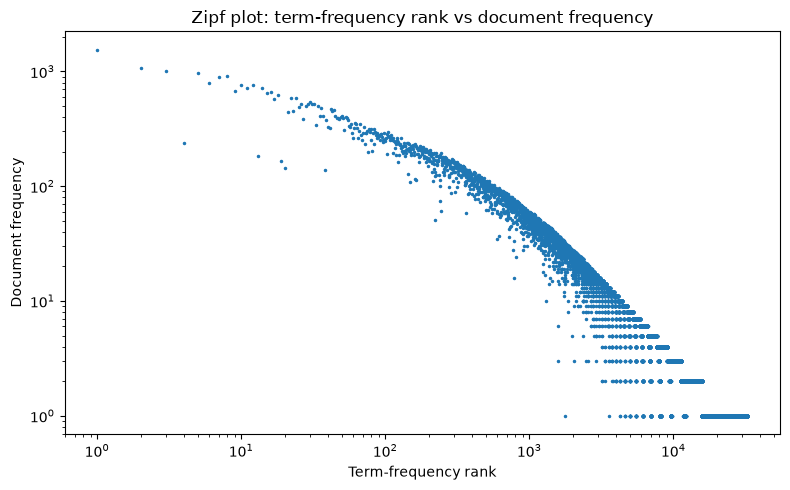

In [12]:
def plot_zipf(tf_df_rows):
    """Zipf plot: term-frequency rank (x) against document frequency (y)."""
    ranks = np.arange(1, len(tf_df_rows) + 1)
    document_frequency = np.array([row[2] for row in tf_df_rows])
    fig, ax = plt.subplots(figsize=(8,5))
    ax.loglog(ranks, document_frequency, marker=".", linestyle="none", markersize=3, color="C0")
    ax.set_xlabel("Term-frequency rank")
    ax.set_ylabel("Document frequency")
    ax.set_title("Zipf plot: term-frequency rank vs document frequency")
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    
plot_zipf(tf_df_rows)

# K-means Model 1, no document-frequency filter

In [13]:
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

n_clusters = 6 # set in question 3

def visualise_text_cluster(n_clusters, cluster_centers, terms, num_word=5):
    # -- Params --
    # cluster_centers: cluster centers of fitted/trained KMeans/other centroid-based clustering
    # terms: terms used for clustering
    # num_word: number of terms to show per cluster. Change as you please.

    # find features/terms closest to centroids
    ordered_centroids = cluster_centers.argsort()[:, ::-1]

    for cluster in range(n_clusters):
        print("Top terms for cluster {}:".format(cluster), end=" ")
        for term_idx in ordered_centroids[cluster, :num_word]:
            print(terms[term_idx], end=", ")
        print()

def describe_clusters(matrix, labels, cluster_centers, terms, titles, n_terms=3, n_central=4):
    """Print one example per top term and the books closest to each centroid"""
    ordered = cluster_centers.argsort()[:, ::-1]
    for cluster in range(cluster_centers.shape[0]):
        mask = labels == cluster
        block = matrix[mask]
        cluster_titles = titles[mask].reset_index(drop=True)
        centroid = np.asarray(block.mean(axis=0)).ravel().reshape(1, -1)
        similarity = cosine_similarity(block, centroid).ravel()

        print("="*80)
        print(f"Cluster {cluster} ({int(mask.sum())} books)")

        for term_idx in ordered[cluster, :n_terms]:
            weights = block[:, term_idx].toarray().ravel()
            heavy = np.flatnonzero(weights >= np.percentile(weights, 90))
            best = heavy[np.argmax(similarity[heavy])]
            print(f"  {terms[term_idx]:<14} -> {cluster_titles.iloc[int(best)]}")

        print("  closest to centroid:")

        for position in np.argsort(-similarity)[:n_central]:
            print(f"    {cluster_titles.iloc[int(position)]}")

        print("="*80)
        print()

def top_terms_table(cluster_centers, terms, num_word=10):
    ordered_centroids = cluster_centers.argsort()[:, ::-1]
    rows = []
    for cluster in range(cluster_centers.shape[0]):
        words = [terms[idx] for idx in ordered_centroids[cluster, :num_word]]
        rows.append({"cluster": cluster, "top_terms": ", ".join(words)})
    return pd.DataFrame(rows)


def cluster_size_table(labels):
    sizes = pd.Series(labels).value_counts().sort_index()
    table = sizes.rename("books").rename_axis("cluster").reset_index()
    table["share"] = (table["books"] / table["books"].sum()).round(3)
    return table

In [14]:
# description has already been preprocessed
# vectorizer_1 = TfidfVectorizer(tokenizer=cab_tokenizer)
vectorizer_1 = TfidfVectorizer(
    tokenizer = lambda tokens: tokens,
    preprocessor= lambda tokens: tokens,
    token_pattern=None
)
X1 = vectorizer_1.fit_transform(books["processed_description"]) # use the preprocessed description
terms_1 = vectorizer_1.get_feature_names_out()

print(f"Model 1 matrix: {X1.shape[0]:,} documents x {X1.shape[1]:,} terms")
print(f"min_df = {vectorizer_1.min_df}, max_df = {vectorizer_1.max_df} (TfidfVectorizer defaults)")
print(f"Non-zero entries: {X1.nnz:,} ({X1.nnz / (X1.shape[0] * X1.shape[1]):.3%} of the matrix)")

Model 1 matrix: 4,989 documents x 32,644 terms
min_df = 1, max_df = 1.0 (TfidfVectorizer defaults)
Non-zero entries: 260,505 (0.160% of the matrix)


In [15]:
# fit K-means with 6 clusters
# n_init=10 fits from 10 random starts, and keeps the lowest inertia
kmeans_1 = KMeans(n_clusters=n_clusters, random_state=rs, n_init=10).fit(X1)
labels_1 = kmeans_1.labels_

print(f"Model 1 fitted with {n_clusters} clusters")
print(f"Inertia: {kmeans_1.inertia_:,.1f}")
print(cluster_size_table(labels_1).to_string(index=False))

Model 1 fitted with 6 clusters
Inertia: 4,855.3
 cluster  books  share
       0    279  0.056
       1    877  0.176
       2    854  0.171
       3   1175  0.236
       4    157  0.031
       5   1647  0.330


In [16]:
# Prac-provided function
visualise_text_cluster(
    kmeans_1.n_clusters, kmeans_1.cluster_centers_, vectorizer_1.get_feature_names_out(), num_word=10
)
print()

# cleaner function
print(top_terms_table(kmeans_1.cluster_centers_, terms_1, num_word=10).to_string(index=False))

Top terms for cluster 0: god, christian, bible, church, life, faith, book, spiritual, christ, testament, 
Top terms for cluster 1: work, history, book, american, political, social, volume, century, study, edition, 
Top terms for cluster 2: book, guide, use, student, include, provide, information, help, new, technique, 
Top terms for cluster 3: story, life, one, woman, love, year, world, new, time, family, 
Top terms for cluster 4: de, en, van, een, het, zijn, op, te, ze, haar, 
Top terms for cluster 5: book, world, war, life, make, include, recipe, collection, new, american, 

 cluster                                                                         top_terms
       0    god, christian, bible, church, life, faith, book, spiritual, christ, testament
       1 work, history, book, american, political, social, volume, century, study, edition
       2    book, guide, use, student, include, provide, information, help, new, technique
       3                     story, life, one, woman

In [17]:
# This should help get a better-suited name for each cluster
describe_clusters(X1, labels_1, kmeans_1.cluster_centers_, terms_1, books["Title"])

Cluster 0 (279 books)
  god            -> Ephesians-Teach Yourself the Bible Series: Epistle Of Christian Maturity
  christian      -> How to Interpret the Bible for Yourself (Leaders Guide)
  bible          -> Ephesians-Teach Yourself the Bible Series: Epistle Of Christian Maturity
  closest to centroid:
    Ephesians-Teach Yourself the Bible Series: Epistle Of Christian Maturity
    What the Bible is All About
    Journey
    How to Interpret the Bible for Yourself (Leaders Guide)

Cluster 1 (877 books)
  work           -> Tabernacle shadows of the "better sacrifices": A helping hand for the royal priesthood
  history        -> A History of World Societies, Vol. 2: Since 1500
  book           -> Democracy Must Work: A Trilateral Agenda for the Decade (The Triangle Papers, 28)
  closest to centroid:
    Social Psychology
    Growth in holiness; or, The progress of the spiritual life
    The cowboy ;: His characteristics, his equipment, and his part in the development of the West
    H

In [18]:
MODEL1_NAMES = {
    0: "Religion",
    1: "History and social science",
    2: "Study and reference guides",
    3: "Romance and family fiction",
    4: "Foreign literature",
    5: "Lifestyle and world books"
}

books["cluster_1"] = labels_1
model1_summary = pd.DataFrame(
    {
        "cluster": list(MODEL1_NAMES),
        "name": list(MODEL1_NAMES.values()),
        "books": [int((labels_1 == cluster).sum()) for cluster in MODEL1_NAMES],
    }
)
model1_summary["share"] = (model1_summary["books"] / len(books)).round(4)
print("Model 1 cluster names:")
print(model1_summary.to_string(index=False))

Model 1 cluster names:
 cluster                       name  books  share
       0                   Religion    279 0.0559
       1 History and social science    877 0.1758
       2 Study and reference guides    854 0.1712
       3 Romance and family fiction   1175 0.2355
       4         Foreign literature    157 0.0315
       5  Lifestyle and world books   1647 0.3301


# K-means Model 2, document-frequency filter

In [19]:
# min_df=3 drops terms that appear fewer than 3 descriptions
# max_df=0.7 drops terms that appear in more than 70% of descriptions
# Again, description is already preprocessed
vectorizer_2 = TfidfVectorizer(
    tokenizer=lambda tokens: tokens,
    preprocessor=lambda tokens: tokens,
    token_pattern=None, 
    min_df=3, 
    max_df=0.7
)
X2 = vectorizer_2.fit_transform(books["processed_description"])
terms_2 = vectorizer_2.get_feature_names_out()

print(f"Model 2 TF-IDF matrix: {X2.shape[0]:,} documents x {X2.shape[1]:,} terms")
print(f"Terms removed relative to Model 1: {X1.shape[1] - X2.shape[1]:,}")
print(f"Terms kept: {X2.shape[1] / X1.shape[1]:.1%}")
print()

df_in_corpus = (tf_df_table.set_index("term")["DF"].reindex(terms_2).fillna(0))

print(
    f"Highest DF among Model 2 terms: {df_in_corpus.max():.0f} "
    f"({df_in_corpus.max() / len(books):.1%} of descriptions)"
)
print(f"Model 2 terms with DF > 70%: {int((df_in_corpus / len(books) > 0.7).sum())}")

Model 2 TF-IDF matrix: 4,989 documents x 10,529 terms
Terms removed relative to Model 1: 22,115
Terms kept: 32.3%

Highest DF among Model 2 terms: 1547 (31.0% of descriptions)
Model 2 terms with DF > 70%: 0


In [20]:
# same initial 10 as model 1 so the models are comparable
kmeans_2 = KMeans(n_clusters=n_clusters, random_state=rs, n_init=10).fit(X2)
labels_2 = kmeans_2.labels_

print(f"Model 2 fitted with {n_clusters} clusters")
print(f"Inertia: {kmeans_2.inertia_:,.1f}")
print(cluster_size_table(labels_2).to_string(index=False))

Model 2 fitted with 6 clusters
Inertia: 4,817.1
 cluster  books  share
       0   1243  0.249
       1   1615  0.324
       2    923  0.185
       3    174  0.035
       4    855  0.171
       5    179  0.036


In [21]:
# Prac-provided function
visualise_text_cluster(
    kmeans_2.n_clusters, kmeans_2.cluster_centers_, vectorizer_2.get_feature_names_out(), num_word=10
)
print()

# cleaner function
print(top_terms_table(kmeans_2.cluster_centers_, terms_2, num_word=10).to_string(index=False))

Top terms for cluster 0: life, woman, love, one, story, world, new, book, find, time, 
Top terms for cluster 1: book, include, make, recipe, present, one, guide, story, offer, travel, 
Top terms for cluster 2: book, use, student, guide, include, provide, edition, text, new, design, 
Top terms for cluster 3: de, en, van, een, het, zijn, te, op, ze, haar, 
Top terms for cluster 4: history, american, war, work, century, book, first, political, world, story, 
Top terms for cluster 5: child, parent, book, family, help, school, kid, play, mother, teacher, 

 cluster                                                                   top_terms
       0                 life, woman, love, one, story, world, new, book, find, time
       1      book, include, make, recipe, present, one, guide, story, offer, travel
       2     book, use, student, guide, include, provide, edition, text, new, design
       3                               de, en, van, een, het, zijn, te, op, ze, haar
       4 history,

In [22]:
# This should help get a better-suited name for each cluster
describe_clusters(X2, labels_2, kmeans_2.cluster_centers_, terms_2, books["Title"])

Cluster 0 (1243 books)
  life           -> The On-Line Bible
  woman          -> All That Glitters
  love           -> The On-Line Bible
  closest to centroid:
    The On-Line Bible
    The God Adventure: Embracing His Power and Purpose for You
    All That Glitters
    The ABC's of Choosing a Good Wife: How to find & marry a great girl

Cluster 1 (1615 books)
  book           -> Life: Enjoy The Ride
  include        -> The Picayune's Creole Cook Book
  make           -> The Picayune's Creole Cook Book
  closest to centroid:
    The Picayune's Creole Cook Book
    Eyewitness Travel Phrase Book: European (14 languages)
    Life: Enjoy The Ride
    Cucina Piemontese: Cooking from Italy's Piedmont

Cluster 2 (923 books)
  book           -> Standard & Poor's MidCap 400 Guide 2000
  use            -> Reporting Technical Information
  student        -> Foundations of Sport & Exercise Psychology
  closest to centroid:
    Foundations of Sport & Exercise Psychology
    Bioinformatics and Funct

In [23]:
MODEL2_NAMES = {
    0: "Romance, family and religious fiction",
    1: "Cooking and travel guides",
    2: "Study and reference guides",
    3: "Foreign literature",
    4: "History and social science",
    5: "Parenting and family books"
}

books["cluster_2"] = labels_2
model2_summary = pd.DataFrame(
    {
        "cluster": list(MODEL2_NAMES),
        "name": list(MODEL2_NAMES.values()),
        "books": [int((labels_2 == cluster).sum()) for cluster in MODEL2_NAMES],
    }
)
model2_summary["share"] = (model2_summary["books"] / len(books)).round(4)
print("Model 2 cluster names:")
print(model2_summary.to_string(index=False))

Model 2 cluster names:
 cluster                                  name  books  share
       0 Romance, family and religious fiction   1243 0.2491
       1             Cooking and travel guides   1615 0.3237
       2            Study and reference guides    923 0.1850
       3                    Foreign literature    174 0.0349
       4            History and social science    855 0.1714
       5            Parenting and family books    179 0.0359


# Comparing the models

In [24]:
import ast
import seaborn as sns
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score

def shared_top_terms(cluster_centers, terms, num_word=10):
    ordered_centroids = cluster_centers.argsort()[:, ::-1]
    counts = Counter()
    for cluster in range(cluster_centers.shape[0]):
        words = [terms[idx] for idx in ordered_centroids[cluster, :num_word]]
        counts.update(set(words))
    shared = sorted(term for term, count in counts.items() if count > 1)
    return shared

shared_1 = shared_top_terms(kmeans_1.cluster_centers_, terms_1, num_word=10)
shared_2 = shared_top_terms(kmeans_2.cluster_centers_, terms_2, num_word=10)

print(f"Model 1 shared top terms ({len(shared_1)}): {shared_1}")
print(f"Model 2 shared top terms ({len(shared_2)}): {shared_2}")

Model 1 shared top terms (6): ['american', 'book', 'include', 'life', 'new', 'world']
Model 2 shared top terms (7): ['book', 'guide', 'include', 'new', 'one', 'story', 'world']


In [25]:
def primary_category(value):
    if pd.isna(value):
        return "(missing)"
    parsed = ast.literal_eval(value)
    if isinstance(parsed, list) and parsed:
        return str(parsed[0])
    return str(parsed)


def category_alignment(labels, categories, names):
    frame = pd.DataFrame({"cluster": labels, "category": categories})
    rows = []
    for cluster, group in frame.groupby("cluster"):
        counts = group["category"].value_counts()
        rows.append(
            {
                "cluster": int(cluster),
                "cluster_name": names[int(cluster)],
                "books": int(len(group)),
                "majority_category": counts.index[0],
                "majority_books": int(counts.iloc[0]),
                "majority_share": round(counts.iloc[0] / len(group), 3),
                "second_category": counts.index[1] if len(counts) > 1 else "",
            }
        )
    table = pd.DataFrame(rows).sort_values("cluster")
    weighted = float(np.average(table["majority_share"], weights=table["books"]))
    return table, weighted

books["primary_category"] = books["categories"].map(primary_category)
align_1, purity_1 = category_alignment(labels_1, books["primary_category"], MODEL1_NAMES)
align_2, purity_2 = category_alignment(labels_2, books["primary_category"], MODEL2_NAMES)

print("Model 1 category alignment:")
print(align_1.to_string(index=False))
print(f"Weighted majority-category share: {purity_1:.3f}")
print()
print("Model 2 category alignment:")
print(align_2.to_string(index=False))
print(f"Weighted majority-category share: {purity_2:.3f}")

Model 1 category alignment:
 cluster               cluster_name  books    majority_category  majority_books  majority_share           second_category
       0                   Religion    279             Religion             176           0.631                   Fiction
       1 History and social science    877              History             139           0.158            Social Science
       2 Study and reference guides    854 Business & Economics             101           0.118                 Computers
       3 Romance and family fiction   1175              Fiction             462           0.393 Biography & Autobiography
       4         Foreign literature    157              Fiction              79           0.503                 (missing)
       5  Lifestyle and world books   1647              Fiction             185           0.112          Juvenile Fiction
Weighted majority-category share: 0.229

Model 2 category alignment:
 cluster                          cluster_name  b

In [26]:
silhouette_sample = 1000
sample_index = np.random.RandomState(rs).choice(
    X1.shape[0], size=silhouette_sample, replace=False
)

silhouette_1 = float(silhouette_score(X1[sample_index], labels_1[sample_index], metric="cosine"))
silhouette_2 = float(silhouette_score(X2[sample_index], labels_2[sample_index], metric="cosine"))

print(f"Fixed random sample: {silhouette_sample:,} documents (random_state={rs})")
print(f"Model 1 cosine silhouette: {silhouette_1:.4f}")
print(f"Model 2 cosine silhouette: {silhouette_2:.4f}")

Fixed random sample: 1,000 documents (random_state=42)
Model 1 cosine silhouette: 0.0108
Model 2 cosine silhouette: 0.0154


Silhouette scores are very weak; clusters overlap or boundaries are unclear

In [27]:
svd_1 = TruncatedSVD(n_components=2, random_state=rs)
xy_1 = svd_1.fit_transform(X1)
svd_2 = TruncatedSVD(n_components=2, random_state=rs)
xy_2 = svd_2.fit_transform(X2)

for name, svd, terms in (("Model 1", svd_1, terms_1), ("Model 2", svd_2, terms_2)):
    ratios = svd.explained_variance_ratio_
    print(f"{name} variance per component: {ratios.round(4)}  total: {ratios.sum():.3f}")

    ordered = svd.components_.argsort()[:, ::-1]
    for component in range(2):
        top = [terms[idx] for idx in ordered[component, :8]]
        print(f"  component {component + 1} top terms: {', '.join(top)}")

    print()

Model 1 variance per component: [0.0025 0.0093]  total: 0.012
  component 1 top terms: book, life, new, work, world, one, include, story
  component 2 top terms: de, en, een, van, het, zijn, op, te

Model 2 variance per component: [0.0027 0.0129]  total: 0.016
  component 1 top terms: book, life, new, work, world, one, story, include
  component 2 top terms: de, en, van, een, het, zijn, op, te



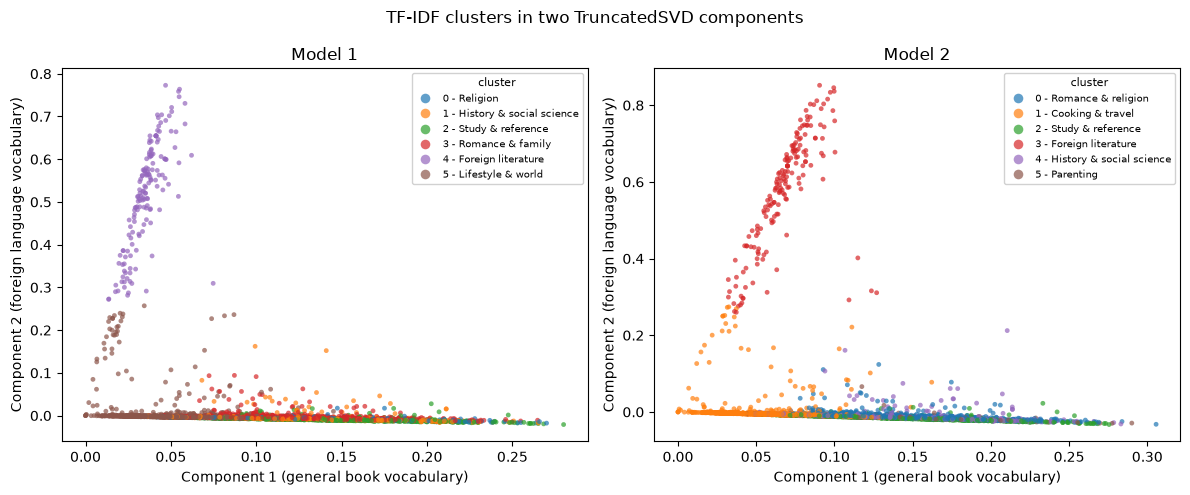

In [28]:
MODEL_1_SHORT = {0: "Religion", 1: "History & social science", 2: "Study & reference",
                 3: "Romance & family", 4: "Foreign literature", 5: "Lifestyle & world"}
MODEL_2_SHORT = {0: "Romance & religion", 1: "Cooking & travel", 2: "Study & reference",
                 3: "Foreign literature", 4: "History & social science", 5: "Parenting"}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, coords, labels, short, title in (
    (axes[0], xy_1, labels_1, MODEL_1_SHORT, "Model 1"),
    (axes[1], xy_2, labels_2, MODEL_2_SHORT, "Model 2"),
):
    legend_order = [f"{cluster} - {short[cluster]}" for cluster in range(n_clusters)]
    named = [f"{cluster} - {short[cluster]}" for cluster in labels]
    plot_frame = pd.DataFrame({"x": coords[:, 0], "y": coords[:, 1], "cluster": named})
    
    sns.scatterplot(
        data=plot_frame,
        x="x",
        y="y",
        hue="cluster",
        hue_order=legend_order,
        s=12,
        linewidth=0,
        alpha=0.7,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Component 1 (general book vocabulary)")
    ax.set_ylabel("Component 2 (foreign language vocabulary)")
    ax.legend(title="cluster", fontsize=7, title_fontsize=8, markerscale=2, loc="upper right", framealpha=0.9)
fig.suptitle("TF-IDF clusters in two TruncatedSVD components")
fig.tight_layout()
plt.show()
plt.close(fig)

comparing models

In [29]:
comparison = pd.DataFrame([
    {
        "model": "Model 1 (no DF filtering)",
        "terms": int(X1.shape[1]),
        "cosine_silhouette_sample": round(silhouette_1, 4),
        "shared_top_terms": len(shared_1),
        "weighted_majority_category_share": round(purity_1, 3),
        "svd_2_components_variance": round(svd_1.explained_variance_ratio_.sum(), 4),
    },
    {
        "model": "Model 2 (min_df=3, max_df=0.7)",
        "terms": int(X2.shape[1]),
        "cosine_silhouette_sample": round(silhouette_2, 4),
        "shared_top_terms": len(shared_2),
        "weighted_majority_category_share": round(purity_2, 3),
        "svd_2_components_variance": round(svd_2.explained_variance_ratio_.sum(), 4),
    },
])
print(comparison.to_string(index=False))

                         model  terms  cosine_silhouette_sample  shared_top_terms  weighted_majority_category_share  svd_2_components_variance
     Model 1 (no DF filtering)  32644                    0.0108                 6                             0.229                     0.0117
Model 2 (min_df=3, max_df=0.7)  10529                    0.0154                 7                             0.203                     0.0156
